# JS07 Lab 1: Klasterisasi Iris dengan K-Means

Jobsheet 07, Lab 1. Dataset Iris di sini diperlakukan seolah tidak punya label, jadi yang dicari adalah kelompok alami di dalam data, bukan kelas yang sudah diketahui.

Alur praktikum mengikuti modul: import library, load dan inspeksi data, seleksi fitur, plotting, membangun model K-Means, evaluasi SSE, lalu menentukan `k` dengan elbow method.


## Langkah 1 - Import Library

`pandas` dan `numpy` untuk mengolah data, `matplotlib` untuk scatter plot, dan `KMeans` dari scikit-learn sebagai algoritma klasterisasinya.


In [1]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


## Langkah 2 - Load dan Inspeksi Data

Muat dataset ke dataframe, lalu lihat lima baris pertama dan profil kolomnya.


In [2]:
df = pd.read_csv('dataset/Iris.csv')
df.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


150 baris, empat kolom bertipe numerik, dan tidak ada nilai kosong. Kolom `Id` cuma nomor urut dan `Species` adalah label asli dataset, dua kolom itu tidak dipakai untuk klasterisasi.


## Langkah 3 - Seleksi Fitur

Pisahkan fitur dari label lewat slicing. `[:, 1:-1]` mengambil kolom `SepalLengthCm` sampai `PetalWidthCm`, sehingga `Id` di kiri dan `Species` di kanan ikut terbuang.


In [4]:
# Features Selection
X = df.iloc[:, 1:-1]  # slice the features
y = df.iloc[:, -1]    # this is the labels (we don't need it)


In [5]:
print(X.head())


   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


## Langkah 4 - Plotting

Scatter plot dua fitur pertama untuk melihat sebaran data. Dari sini kita menebak jumlah cluster secara visual.


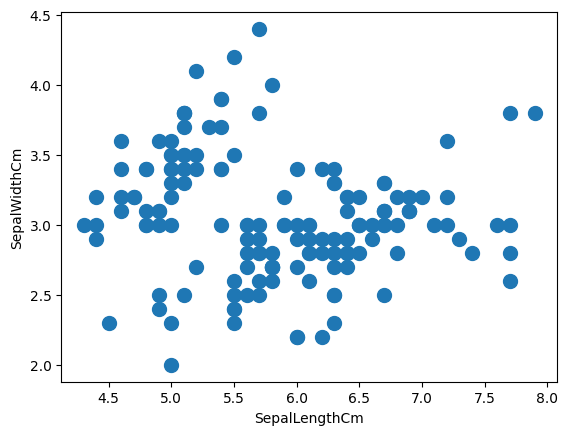

In [6]:
# Make a scatterplot using
# SepalLengthCm and SepalWidthCm
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.show()


Sebaran titik mengumpul di dua wilayah, satu di kiri bawah dan satu lagi lebih ke kanan. Tebakan awalnya data ini punya dua cluster, padahal label aslinya ada tiga kelas.


## Langkah 5 - Membuat Model K-Means

Model dibangun dengan `n_clusters=2` sesuai amatan pada scatter plot. `fit_predict()` sekaligus melatih model dan mengembalikan nomor cluster tiap baris.


In [7]:
# Build a K-Means Model
# Based on visual inspection using scatterplot,
# we can assumpt that the data has 2 cluster
# (even though, from the label, there are 3 labels in this data)
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)


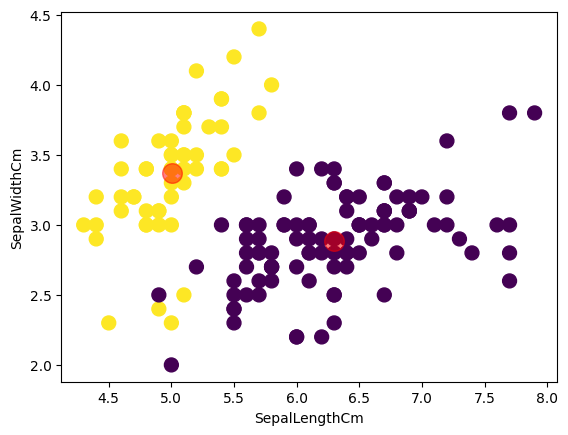

In [8]:
# Plot the clustering result
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.show()


Titik merah menandai centroid hasil iterasi K-Means. Dua cluster terbentuk, dan centroid-nya berada di tengah masing-masing kelompok.


## Langkah 6 - Evaluasi Model

Metrik yang dipakai adalah SSE (sum of squared error), diakses lewat properti `inertia_` dari objek K-Means yang sudah dilatih.


In [9]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')


Nilai SSE: 152.3479517603579


Nilai SSE-nya bergantung pada posisi centroid awal yang acak, jadi angkanya bisa berbeda antar run. Di sini `random_state=42` dipasang supaya hasilnya konsisten.


## Langkah 7 - Menentukan `k` Terbaik dengan Elbow Method

Kalau jumlah cluster belum ditentukan, SSE bisa dihitung untuk beberapa nilai `k` lalu digambar sebagai line plot. Titik "elbow", tempat penurunan SSE mulai melandai, menjadi dasar pemilihan `k`.


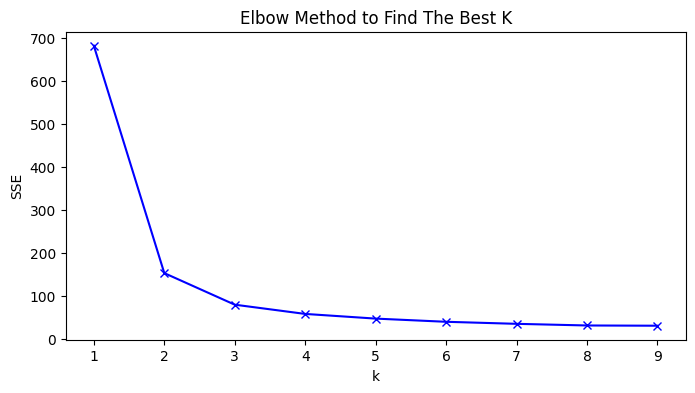

In [10]:
# Find the best k
# using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1, 10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()


In [11]:
for k, nilai in zip(K, sse):
    print(f'k={k}: SSE={nilai:.4f}')


k=1: SSE=681.3706
k=2: SSE=152.3480
k=3: SSE=78.8557
k=4: SSE=57.3509
k=5: SSE=46.4722
k=6: SSE=39.0660
k=7: SSE=34.3058
k=8: SSE=30.4762
k=9: SSE=29.9062


SSE selalu mengecil saat `k` bertambah, karena anggota tiap cluster makin sedikit dan clusternya makin sempit. Jadi cluster terbaik bukan yang SSE-nya paling kecil, tapi posisi di mana penurunan tajam berubah menjadi penurunan yang landai.

Pada data ini penurunan dari `k=1` ke `k=3` sangat besar, sementara setelah `k=3` garisnya melandai. Nilai `k=3` inilah pilihan yang paling masuk akal, dan kebetulan cocok dengan tiga spesies di dataset aslinya.


## Kesimpulan

Model K-Means dengan `k=2` berhasil memisahkan data menjadi dua kelompok, tetapi elbow method menunjukkan `k=3` sebagai jumlah cluster yang lebih tepat. SSE dipakai sebagai alat bantu memilih `k`, bukan sebagai skor akhir, karena nilainya terus turun setiap kali cluster ditambah.
